<a href="https://colab.research.google.com/github/yanapatt/MarisaNeXt/blob/main/notebooks/MushroomB/ConvNeXt_Tiny_M_D4_224_MushroomB_R1_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [ ]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [ ]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomB'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

modify_type = 'D4'
model_name_path = f'convnext_tiny_modify_{modify_type}_224_r1_v1' # เปลี่ยนเสมอ
model_name = 'ConvNeXt-Tiny' # เปลี่ยนเสมอ

sigle_model_title = f'{model_name} Modify-{modify_type} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Modify-{modify_type} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'myModelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [ ]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

In [ ]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.12.12
Sun Mar 22 02:56:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   36C    P8             16W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [ ]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 16
Dataset has been extracted to /content/MushroomB


## **Section 2: Define model architecture**

In [ ]:
model_fn = partial(
    models.build_modify_convnext,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    target_stages=[0,1,2,3],
    freeze_backbone=False,
    modify_type=modify_type
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Layer (type:depth-idx)                                  Output Shape              Param #
ConvNeXt                                                [1, 16]                   --
├─Sequential: 1-1                                       [1, 96, 56, 56]           --
│    └─Conv2d: 2-1                                      [1, 96, 56, 56]           4,704
│    └─LayerNorm2d: 2-2                                 [1, 96, 56, 56]           192
├─Sequential: 1-2                                       [1, 768, 7, 7]            --
│    └─ConvNeXtStage: 2-3                               [1, 96, 56, 56]           --
│    │    └─Identity: 3-1                               [1, 96, 56, 56]           --
│    │    └─Sequential: 3-2                             [1, 96, 56, 56]           237,888
│    └─ConvNeXtStage: 2-4                               [1, 192, 28, 28]          --
│    │    └─Sequential: 3-3                             [1, 192, 28, 28]          74,112
│    │    └─Sequential: 3-4                    

## **Section 3: Preparing the dataset**

**Configuration for training**

In [ ]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BICUBIC
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.3, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Amanita_Caesarea-Edible', 'Amanita_Citrina-Edible', 'Amanita_Pantherina-NotEdible', 'Boletus_Regius-Edible', 'Clitocybe_Costata-Edible', 'Entoloma_Lividum-NotEdible', 'Gyromitra_Esculenta-NotEdible', 'Helvella_Crispa-Edible', 'Hydnum_Rufescens-NotEdible', 'Hygrophorus_Latitabundus-Edible', 'Morchella_Deliciosa-Edible', 'Omphalotus_Olearius-NotEdible', 'Phallus_Impudicus-NotEdible', 'Rubroboletus_Satanas-NotEdible', 'Russula_Cyanoxantha-Edible', 'Russula_Delica-NotEdible']
Class to Index    : {'Amanita_Caesarea-Edible': 0, 'Amanita_Citrina-Edible': 1, 'Amanita_Pantherina-NotEdible': 2, 'Boletus_Regius-Edible': 3, 'Clitocybe_Costata-Edible': 4, 'Entoloma_Lividum-NotEdible': 5, 'Gyromitra_Esculenta-NotEdible': 6, 'Helvella_Crispa-Edible': 7, 'Hydnum_Rufescens-NotEdible': 8, 'Hygrophorus_Latitabundus-Edible': 9, 'Morchella_Deliciosa-Edible': 10, 'Ompha

## **Section 4: Training the model**

In [ ]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB' successfully.


In [ ]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
60/60 [==============================] - 30s 500ms/step - loss: 2.2279 - lr: 1.0000e-04 - accuracy: 0.4330 - f1: 0.3625 - precision: 0.5720 - recall: 0.3588
Epoch 1/30 | val_loss: 1.2297 - val_accuracy: 0.8500 - val_f1: 0.8020 - val_precision: 0.8211 - val_recall: 0.8064
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8500, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/fold_1/convnext_tiny_modify_D4_224_r1_v1_MushroomB_best_weight.pth
Epoch: 2/30
60/60 [==============================] - 22s 371ms/step - loss: 0.7454 - lr: 9.9726e-05 - accuracy: 0.8937 - f1: 0.8755 - precision: 0.8919 - recall: 0.8687
Epoch 2/30 | val_loss: 0.3396 - val_accuracy: 0.9646 - val_f1: 0.9603 - val_precision: 0.9635 - val_recall: 0.9604
[Logs] Epoch: 2 val_accuracy improve

Epoch: 1/30
60/60 [==============================] - 23s 375ms/step - loss: 2.1497 - lr: 1.0000e-04 - accuracy: 0.4747 - f1: 0.4107 - precision: 0.5510 - recall: 0.4048
Epoch 1/30 | val_loss: 1.1729 - val_accuracy: 0.8625 - val_f1: 0.8084 - val_precision: 0.8885 - val_recall: 0.8131
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8625, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/fold_4/convnext_tiny_modify_D4_224_r1_v1_MushroomB_best_weight.pth
Epoch: 2/30
60/60 [==============================] - 23s 380ms/step - loss: 0.7449 - lr: 9.9726e-05 - accuracy: 0.8947 - f1: 0.8736 - precision: 0.9013 - recall: 0.8692
Epoch 2/30 | val_loss: 0.3150 - val_accuracy: 0.9708 - val_f1: 0.9655 - val_precision: 0.9653 - val_recall: 0.9670
[Logs] Epoch: 2 val_accuracy improved from 0.8625 to 0.9708, saving model to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_Mushroo

## **Section 5: Individual model performance**

In [ ]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

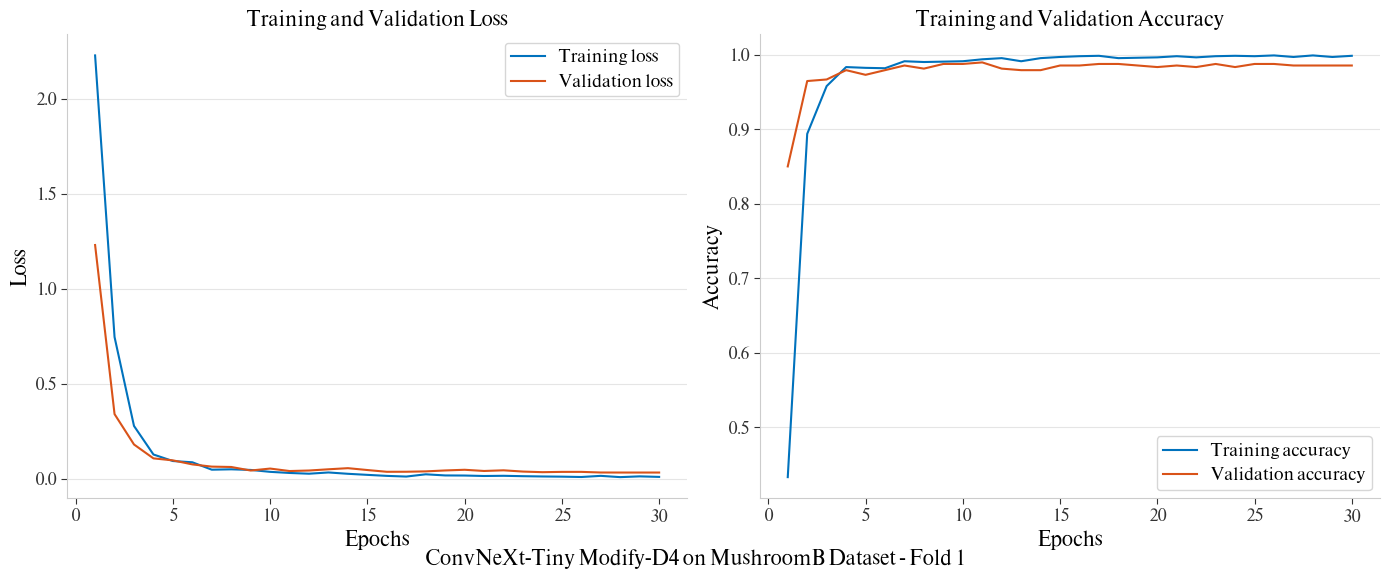

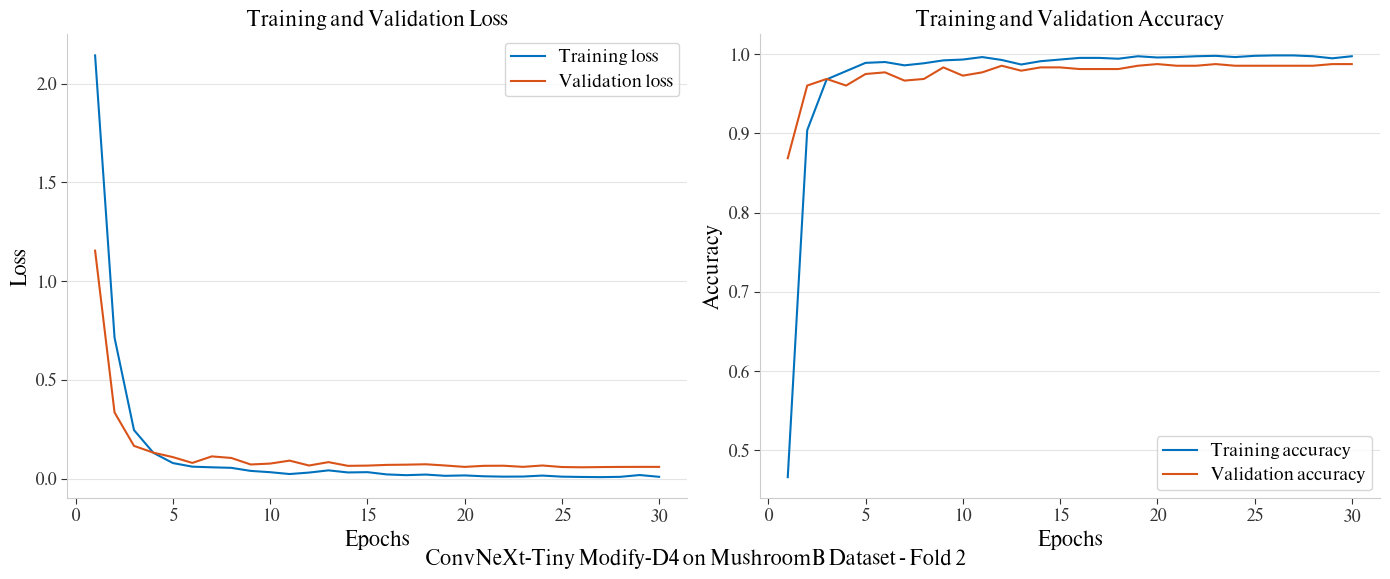

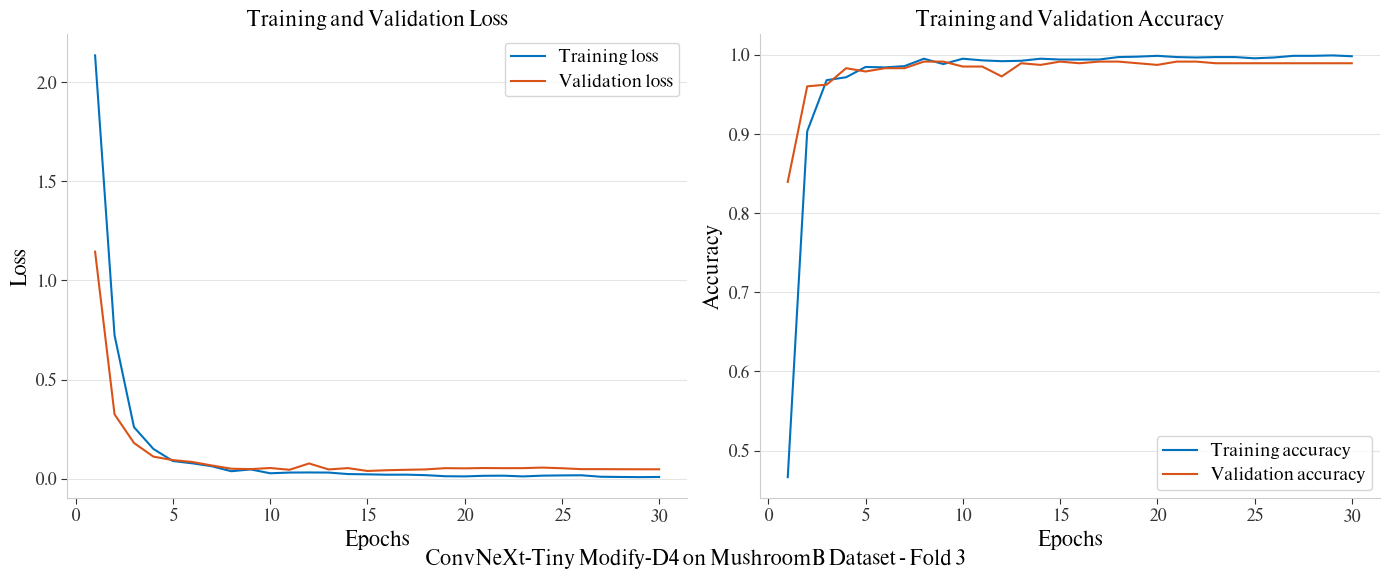

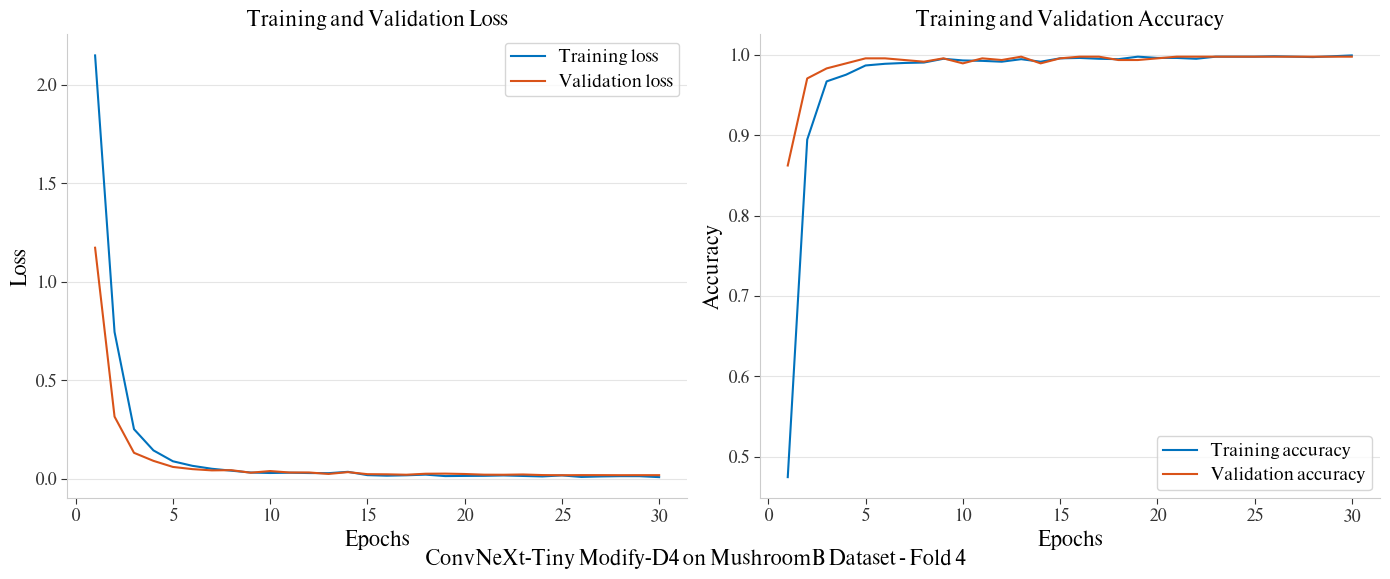

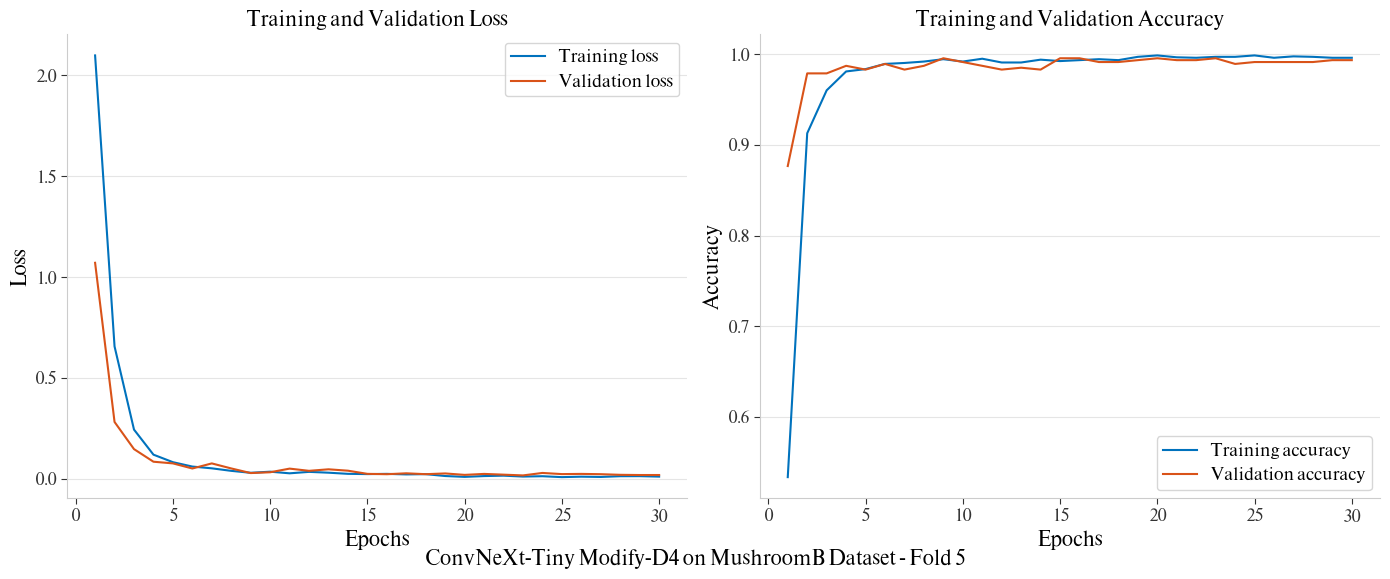

In [ ]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

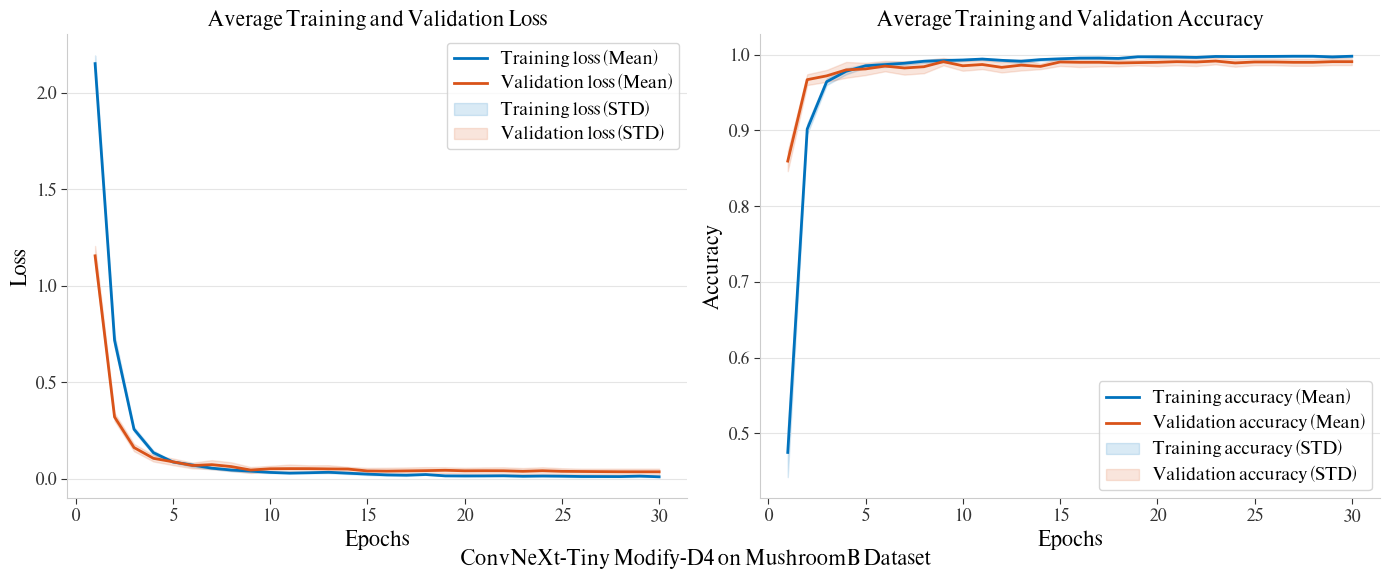

In [ ]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [ ]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)

[*] Evaluating Fold 1/5 on its Validation Set...
15/15 [==============================] - 3s 214ms/step - loss: 0.0399 - accuracy: 0.9896 - f1: 0.9872 - precision: 0.9866 - recall: 0.9887
[*] Evaluating Fold 2/5 on its Validation Set...
15/15 [==============================] - 4s 274ms/step - loss: 0.0599 - accuracy: 0.9875 - f1: 0.9844 - precision: 0.9855 - recall: 0.9838
[*] Evaluating Fold 3/5 on its Validation Set...
15/15 [==============================] - 4s 300ms/step - loss: 0.0503 - accuracy: 0.9917 - f1: 0.9898 - precision: 0.9911 - recall: 0.9888
[*] Evaluating Fold 4/5 on its Validation Set...
15/15 [==============================] - 4s 244ms/step - loss: 0.0239 - accuracy: 0.9979 - f1: 0.9970 - precision: 0.9970 - recall: 0.9970
[*] Evaluating Fold 5/5 on its Validation Set...
15/15 [==============================] - 4s 282ms/step - loss: 0.0294 - accuracy: 0.9958 - f1: 0.9949 - precision: 0.9947 

### **On test set**

In [ ]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
19/19 [==============================] - 7s 390ms/step

[Inference Report] Latency: 183.35 ms/batch | Throughput: 172.23 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
19/19 [==============================] - 5s 276ms/step

[Inference Report] Latency: 74.07 ms/batch | Throughput: 426.36 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyD

In [ ]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.064171  0.983333 0.981889   0.983411 0.981282
Fold 2 0.051917  0.990000 0.989241   0.989771 0.989203
Fold 3 0.064006  0.985000 0.981995   0.982620 0.981916
Fold 4 0.068564  0.981667 0.981942   0.982296 0.982468
Fold 5 0.062014  0.983333 0.981956   0.983205 0.980961
  Mean 0.062134  0.984667 0.983405   0.984260 0.983166
   STD 0.006192  0.003206 0.003263   0.003113 0.003424
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [ ]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/myModelWeights/MushroomB/convnext_tiny_modify_D4_224_r1_v1_MushroomB/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [ ]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     1.0000    1.0000    1.0000        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9630    0.9811        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Latitabundus-Edible     1.0000    1.0000    1.0000        26
     Morchella_Deliciosa-Edible     0.9800    1.0000    0.9899        49
  Omphalotus_Olearius-NotEdible     1.0000    1.0000    1.0000        29
    Phallus_Impu

### **Correct predictions**

In [ ]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [ ]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.996643
1,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.998036
2,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.996815
3,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997622
4,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997942
...,...,...,...,...,...,...
590,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.991622
591,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.992044
592,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.995976
593,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.992923


### **Incorrect predictions**

In [ ]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Citrina-Edible...,Russula_Cyanoxantha-Edible,Amanita_Citrina-Edible,14,1,0.483076
1,/content/MushroomB/test/Amanita_Citrina-Edible...,Amanita_Pantherina-NotEdible,Amanita_Citrina-Edible,2,1,0.722624
2,/content/MushroomB/test/Clitocybe_Costata-Edib...,Entoloma_Lividum-NotEdible,Clitocybe_Costata-Edible,5,4,0.878068
3,/content/MushroomB/test/Gyromitra_Esculenta-No...,Morchella_Deliciosa-Edible,Gyromitra_Esculenta-NotEdible,10,6,0.996729
4,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Delica-NotEdible,Russula_Cyanoxantha-Edible,15,14,0.447480


### **Confusion matrix**

#### **without Normalize**

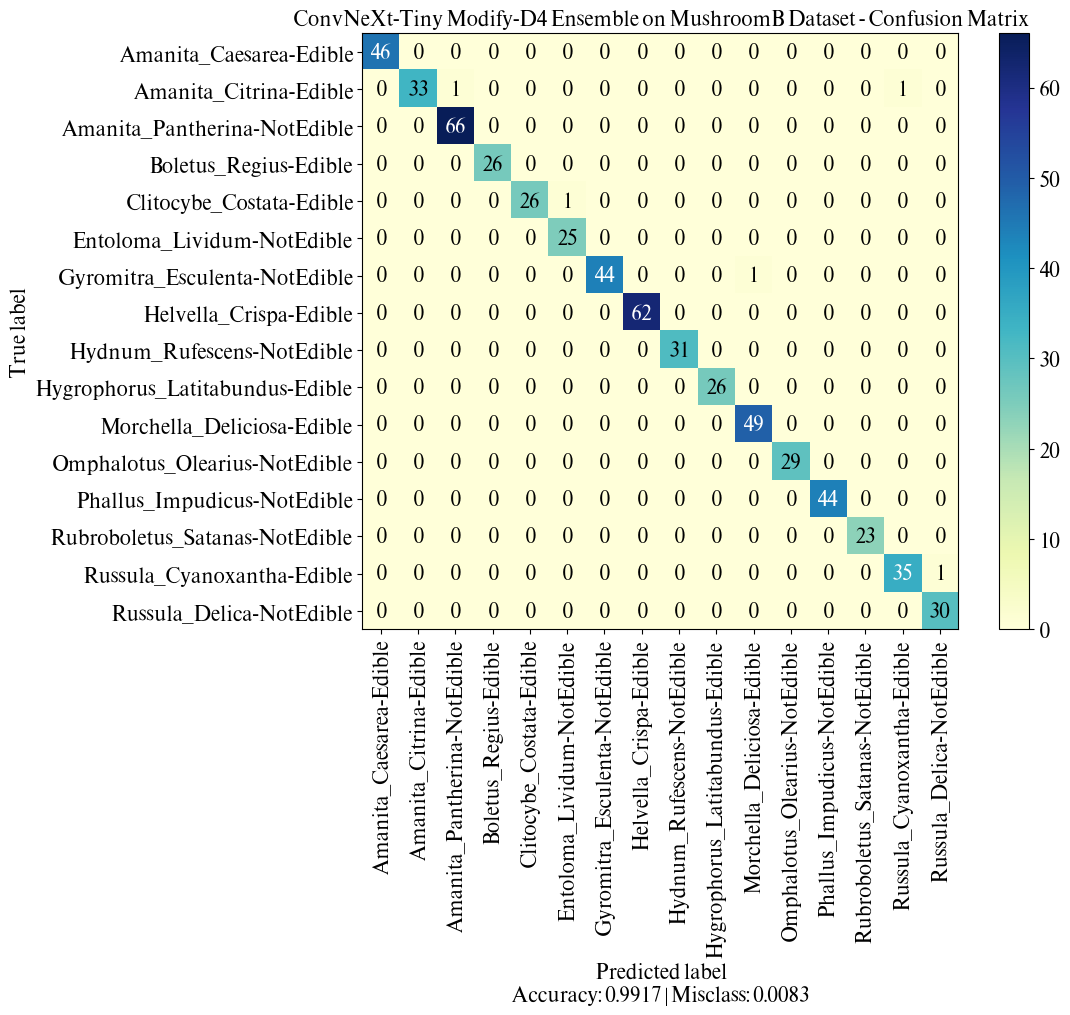

In [ ]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

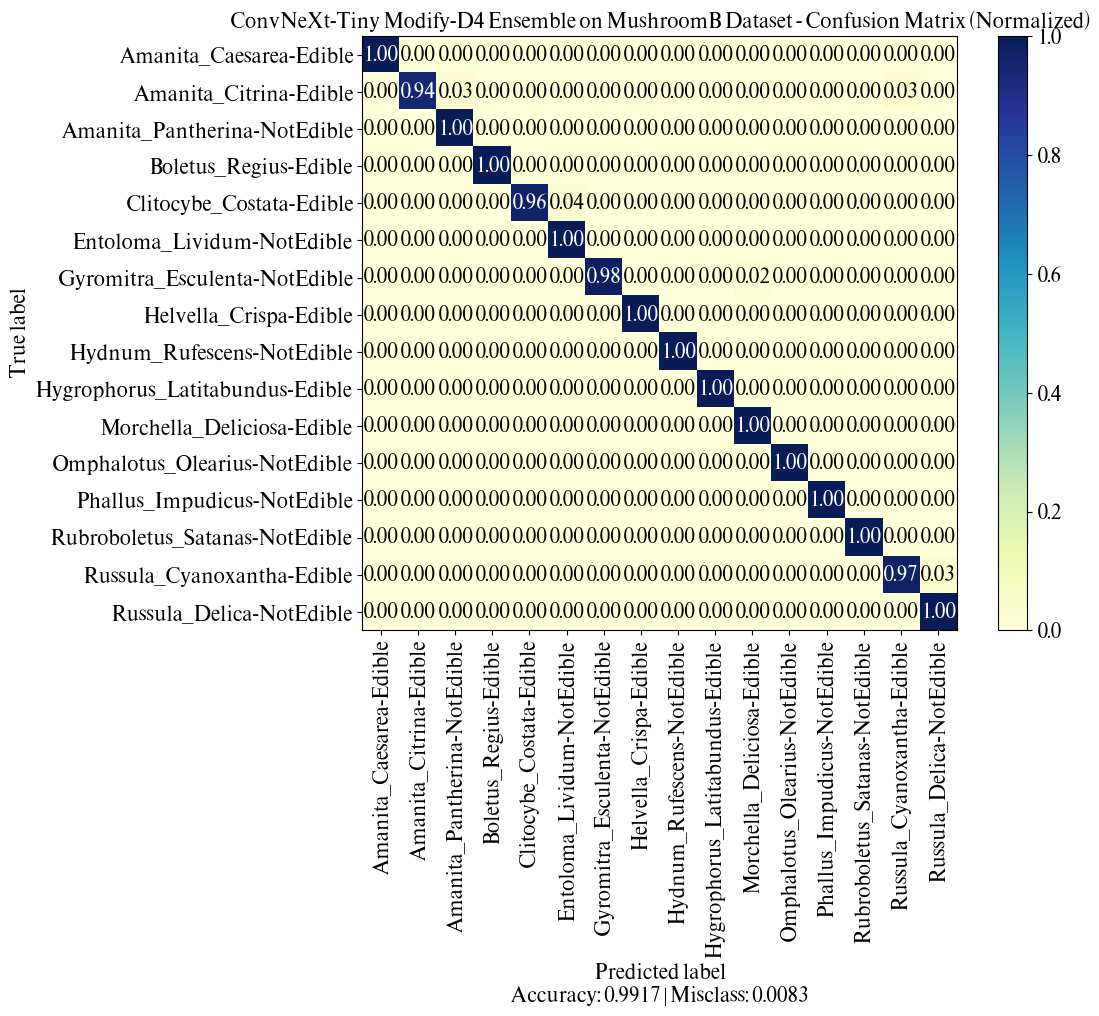

In [ ]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

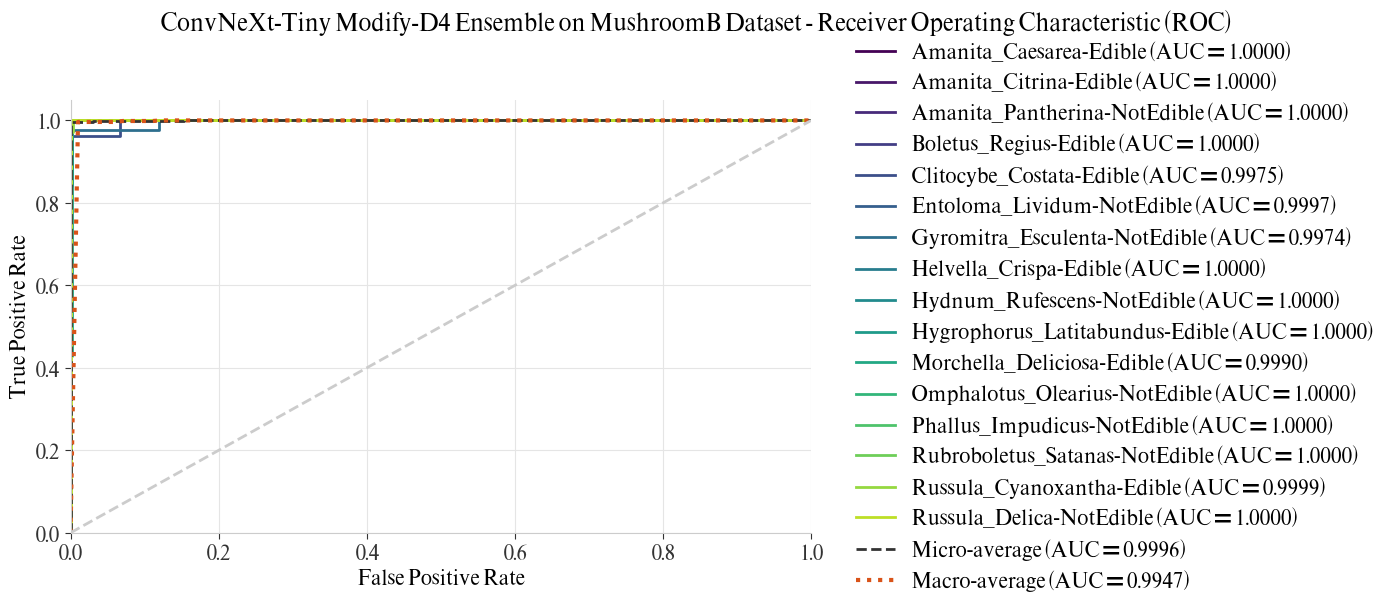

In [ ]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [ ]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.stages[-1].blocks[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 4
       Primary Metric: accuracy->0.9979 | Secondary: loss->0.0239 on Validation set.
[ConvNeXtBlockModify(
  (conv_dw): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (pre_attn): SimAM(lambda=0.000100)
  (mlp): MlpWithMiddleAttention(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (middle_attn): SimAM(lambda=0.000100)
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (post_attn): Identity()
  (shortcut): Identity()
  (drop_path): Identity()
)]


In [ ]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
unique_label

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Boletus_Regius-Edible/...,Boletus_Regius-Edible,Boletus_Regius-Edible,3,3,0.997353
1,/content/MushroomB/test/Amanita_Pantherina-Not...,Amanita_Pantherina-NotEdible,Amanita_Pantherina-NotEdible,2,2,0.998482
2,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Cyanoxantha-Edible,Russula_Cyanoxantha-Edible,14,14,0.996642
3,/content/MushroomB/test/Helvella_Crispa-Edible...,Helvella_Crispa-Edible,Helvella_Crispa-Edible,7,7,0.998135
4,/content/MushroomB/test/Morchella_Deliciosa-Ed...,Morchella_Deliciosa-Edible,Morchella_Deliciosa-Edible,10,10,0.997952
5,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997525
6,/content/MushroomB/test/Omphalotus_Olearius-No...,Omphalotus_Olearius-NotEdible,Omphalotus_Olearius-NotEdible,11,11,0.990162
7,/content/MushroomB/test/Hygrophorus_Latitabund...,Hygrophorus_Latitabundus-Edible,Hygrophorus_Latitabundus-Edible,9,9,0.994168
8,/content/MushroomB/test/Amanita_Citrina-Edible...,Amanita_Citrina-Edible,Amanita_Citrina-Edible,1,1,0.993885
9,/content/MushroomB/test/Entoloma_Lividum-NotEd...,Entoloma_Lividum-NotEdible,Entoloma_Lividum-NotEdible,5,5,0.901141


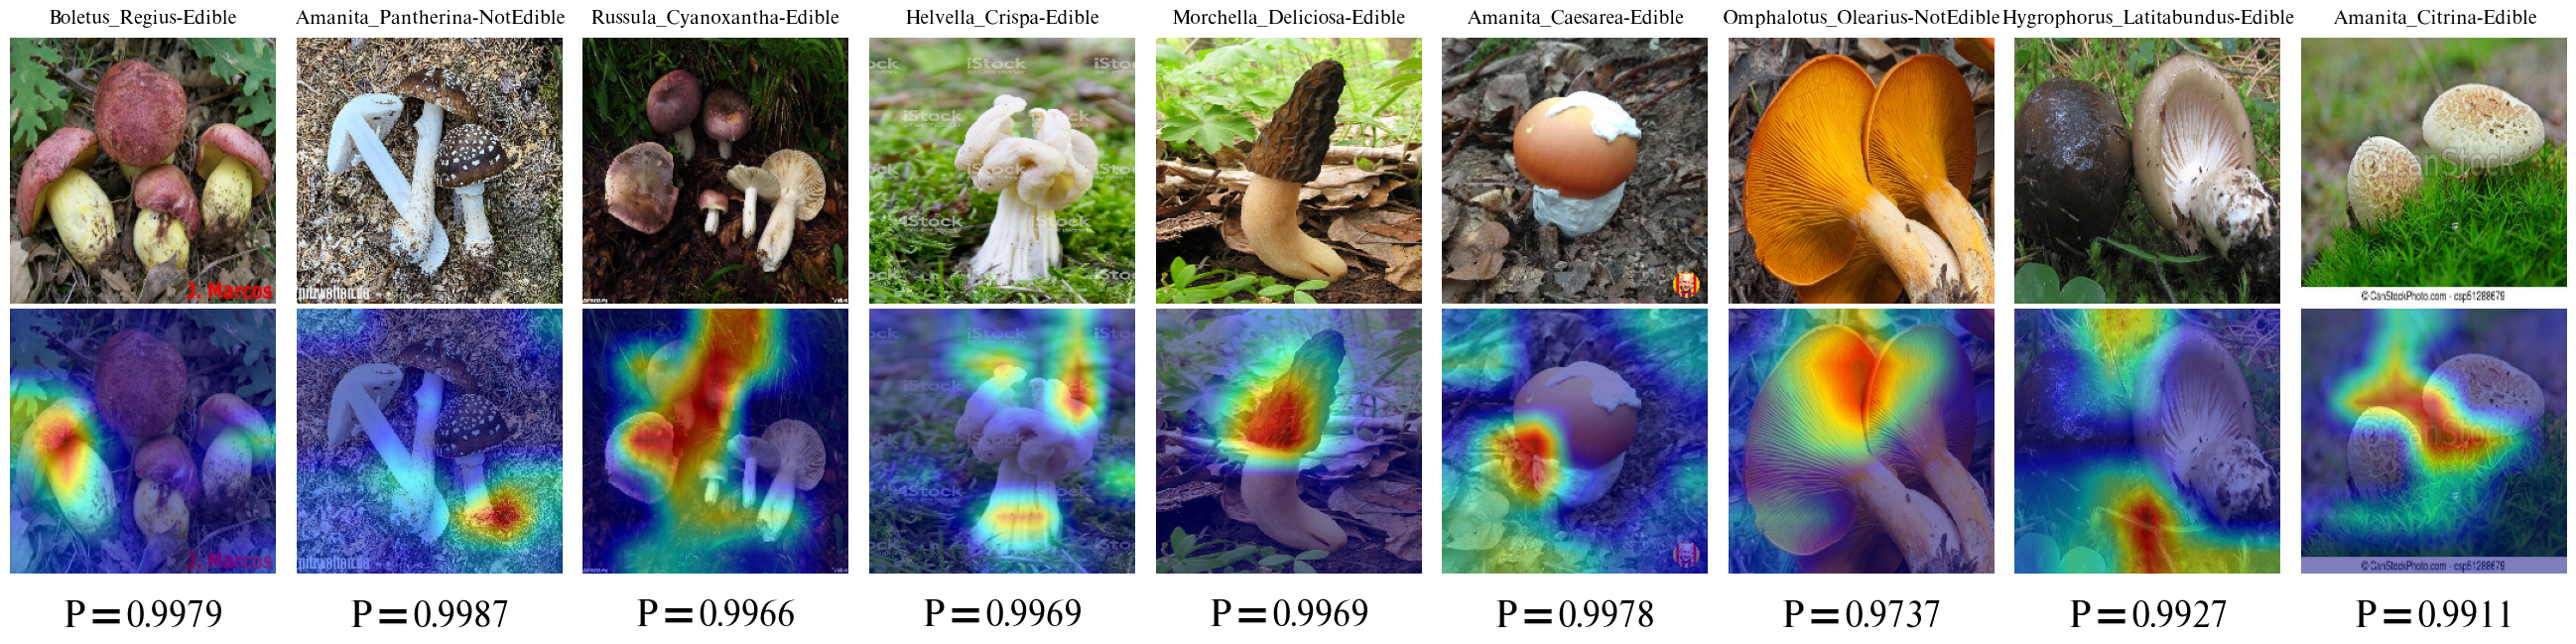

In [ ]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label[:9],
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=3,
    row_one_title=True,
    fontsize=24,
    save_path=model_ensem_dir,
    titlesize=13
)

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [ ]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.039874,0.989583,0.987181,0.986553,0.988749
Fold 2,0.059893,0.987500,0.984442,0.985482,0.983830
Fold 3,0.050269,0.991667,0.989796,0.991056,0.988830
Fold 4,0.023909,0.997917,0.996951,0.997024,0.997024
Fold 5,0.029367,0.995825,0.994899,0.994659,0.995345
Mean,0.040662,0.992498,0.990654,0.990955,0.990756
STD,0.014756,0.004318,0.005221,0.004997,0.005386


##### **Performace on Test Set (N Folds)**

In [ ]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.064171,0.983333,0.981889,0.983411,0.981282
Fold 2,0.051917,0.990000,0.989241,0.989771,0.989203
Fold 3,0.064006,0.985000,0.981995,0.982620,0.981916
Fold 4,0.068564,0.981667,0.981942,0.982296,0.982468
Fold 5,0.062014,0.983333,0.981956,0.983205,0.980961
Mean,0.062134,0.984667,0.983405,0.984260,0.983166
STD,0.006192,0.003206,0.003263,0.003113,0.003424


##### **Performace on Test Set (Ensemble)**

In [ ]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.052809,0.991667,0.991193,0.991661,0.990989


#### **Model Info**

In [ ]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.9379,4.4548,27.8324,2.332993,73.673470,428.646780
